<a href="https://colab.research.google.com/github/elonsobrevilla06-byte/Youtube_Virality/blob/main/YoutubeViralOrNot_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

# 1.) Acquiring Data

In [3]:
path = kagglehub.dataset_download("vedauv/what-makes-a-yt-video-go-viral-12000-vids")
df = pd.read_csv(f"{path}/viral_videos.csv")


100%|██████████| 330k/330k [00:00<00:00, 396kB/s]

Extracting files...


In [4]:
df.head()

,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1


In [5]:
df.describe()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,12000.000000
mean,631.619583,54.524000,0.400250,11.539417,14.586833,508.919417,1.009487e+06,7.677524e+05,3.750578e+04,4.739626e+03,9.503240e+03,0.200000
std,285.825411,14.950788,0.489969,6.914424,7.741422,287.212933,2.585562e+06,3.526908e+06,1.823115e+05,2.331387e+04,4.644499e+04,0.400017
min,30.000000,10.000000,0.000000,0.000000,0.000000,0.000000,3.636000e+03,1.390000e+02,6.000000e+00,0.000000e+00,1.000000e+00,0.000000
25%,408.000000,45.000000,0.000000,5.000000,9.000000,300.000000,1.585215e+05,6.123550e+04,2.790000e+03,3.167500e+02,6.417500e+02,0.000000
50%,614.000000,55.000000,0.000000,12.000000,14.000000,504.000000,3.813820e+05,1.852680e+05,8.751500e+03,1.018000e+03,2.050500e+03,0.000000
75%,822.000000,65.000000,1.000000,18.000000,20.000000,709.000000,9.298448e+05,5.569705e+05,2.657125e+04,3.207250e+03,6.527250e+03,0.000000
max,1960.000000,109.000000,1.000000,23.000000,44.000000,1618.000000,1.000000e+08,1.994657e+08,1.159287e+07,1.116186e+06,2.367174e+06,1.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   video_id            12000 non-null  object
 1   category            12000 non-null  object
 2   duration_sec        12000 non-null  int64 
 3   title_length        12000 non-null  int64 
 4   thumbnail_face      12000 non-null  int64 
 5   upload_hour         12000 non-null  int64 
 6   upload_day          12000 non-null  object
 7   tags_count          12000 non-null  int64 
 8   description_length  12000 non-null  int64 
 9   subscriber_count    12000 non-null  int64 
 10  views               12000 non-null  int64 
 11  likes               12000 non-null  int64 
 12  comments            12000 non-null  int64 
 13  shares              12000 non-null  int64 
 14  viral               12000 non-null  int64 
dtypes: int64(12), object(3)
memory usage: 1.4+ MB


In [7]:
#getting all the object columns and int columns
object_columns = []
int_columns = []

for col in df.columns:
  if df[col].dtype == "object":
    object_columns.append(col)
  else:
    int_columns.append(col)

binary_cols = []
for c in int_columns:
  if df[c].isin([0,1]).all():
    binary_cols.append(c)





In [8]:
print("Object Columns: ", object_columns)
print("int Columns: ", int_columns)
print("Binary Columns: ", binary_cols)

Object Columns:  ['video_id', 'category', 'upload_day']
int Columns:  ['duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'tags_count', 'description_length', 'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral']
Binary Columns:  ['thumbnail_face', 'viral']


# 2.) Data Cleaning

In [9]:
#Checking if theres any na value
df.isna().any(axis = None)
df.isna().sum()

,0
video_id,0
category,0
duration_sec,0
title_length,0
thumbnail_face,0
upload_hour,0
upload_day,0
tags_count,0
description_length,0
subscriber_count,0


In [10]:
#Check for duplicate
print(df.duplicated().sum())
df[df.duplicated()]

#If theres any duplicate
#df = df.drop_duplicates()

0


,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral


In [11]:
#Check Unique for every columns
for col in df.columns:
  print(f"\n--{col}--")
  print(df[col].unique())


--video_id--
['vid_000001' 'vid_000002' 'vid_000003' ... 'vid_011998' 'vid_011999'
 'vid_012000']

--category--
['Beauty' 'Tech' 'Fitness' 'Cooking' 'Education' 'Finance' 'Music'
 'Comedy' 'News' 'DIY' 'Travel' 'Science' 'Vlog' 'Gaming' 'Sports']

--duration_sec--
[ 517  495  311 ... 1380 1230 1552]

--title_length--
[ 64  47  76  69  58  31  70  41  15  66  44  50  55  56  36  67  51  71
  89  35  43  73  48  42  54  75  62  87  60  29  59  78  68  79  53  45
  63  30  26  28  20  14  52  65  22  34  49  61  74  57  85  77  33  81
  46  38  32  18  40  21  39  23  37  27  10  91  25  72  80  94  88  16
  82  24  84  92  19  90  83  93  99  13  17  96  86 104  95  98 108  11
  12 101 102 100 106 109 105  97 103]

--thumbnail_face--
[1 0]

--upload_hour--
[23 17  0 19 20 14 13 10 11  1 12 18 21  2 15  4  3  8  9  5 16  7 22  6]

--upload_day--
['Wed' 'Mon' 'Sat' 'Fri' 'Sun' 'Tue' 'Thu']

--tags_count--
[27 10 13 17  0 21 22 12 18 34  8  4 16 24 20 23 25 14 15 11 19  3  6  9
 26  5 28 3

# 3.) EDA

Index(['video_id', 'category', 'duration_sec', 'title_length',
       'thumbnail_face', 'upload_hour', 'upload_day', 'tags_count',
       'description_length', 'subscriber_count', 'views', 'likes', 'comments',
       'shares', 'viral'],
      dtype='object')


(12000, 15)

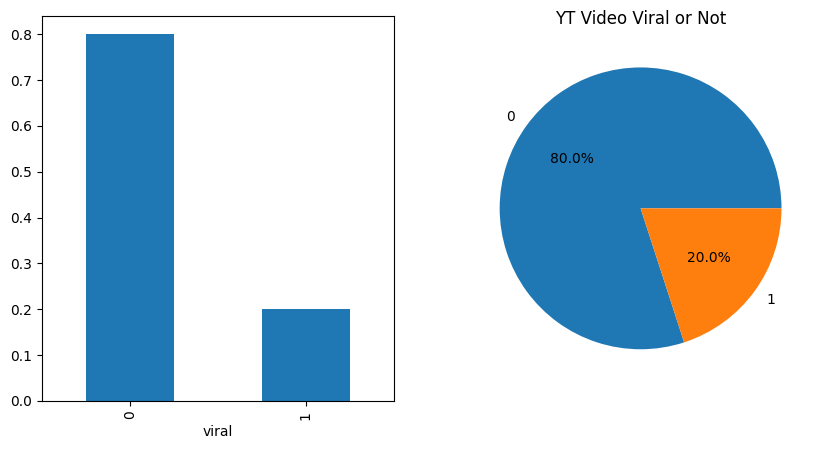

In [12]:
print(df.columns)
fig, axes = plt.subplots(1,2, figsize = (10, 5))

df["viral"].value_counts(normalize = True).plot(kind = "bar", ax = axes[0])
df['viral'].value_counts(normalize = True).plot(
    kind = "pie",
    title = "YT Video Viral or Not",
    ylabel = '',
     autopct = '%1.1f%%',
     ax = axes[1],
)
df.shape


In [13]:
df = df.drop(columns = "video_id")
df.columns

Index(['category', 'duration_sec', 'title_length', 'thumbnail_face',
       'upload_hour', 'upload_day', 'tags_count', 'description_length',
       'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral'],
      dtype='object')

array([[<Axes: title={'center': 'duration_sec'}>,
        <Axes: title={'center': 'title_length'}>,
        <Axes: title={'center': 'thumbnail_face'}>],
       [<Axes: title={'center': 'upload_hour'}>,
        <Axes: title={'center': 'tags_count'}>,
        <Axes: title={'center': 'description_length'}>],
       [<Axes: title={'center': 'subscriber_count'}>,
        <Axes: title={'center': 'views'}>,
        <Axes: title={'center': 'likes'}>],
       [<Axes: title={'center': 'comments'}>,
        <Axes: title={'center': 'shares'}>,
        <Axes: title={'center': 'viral'}>]], dtype=object)

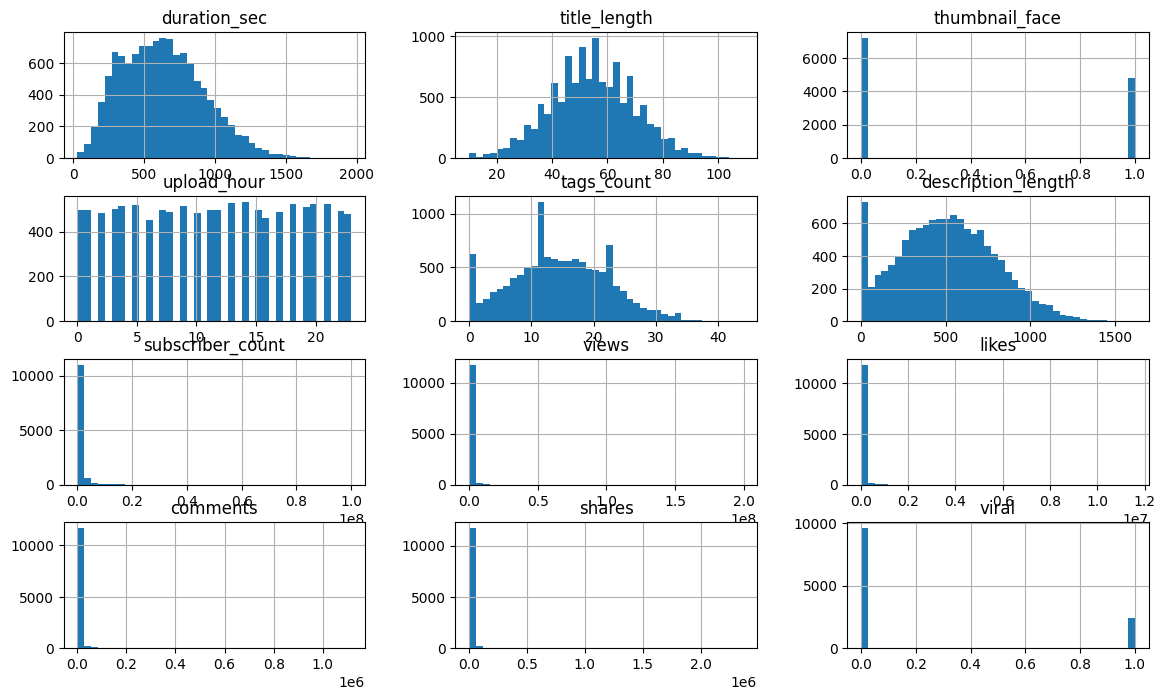

In [14]:
df[int_columns].hist(bins = 40, figsize = (14,8))


In [15]:
df.groupby("viral")[int_columns].mean()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
viral,,,,,,,,,,,,
0,653.963542,54.518958,0.386354,11.488854,14.474479,510.598854,4.743781e+05,1.875680e+05,9433.804167,1173.837083,2374.761250,0.0
1,542.243750,54.544167,0.455833,11.741667,15.036250,502.201667,3.149921e+06,3.088490e+06,149793.697500,19002.782083,38017.155833,1.0


In [16]:
df.groupby("viral")["likes"].count()

,likes
viral,
0,9600
1,2400


In [17]:
pd.crosstab(df["viral"], df["likes"]).T

viral,0,1
likes,,
6,1,0
19,1,0
22,1,0
28,1,0
30,1,0
...,...,...
4354977,0,1
5338524,0,1
5937206,0,1


In [18]:
# object_columns = object_columns.remove("video_id")



In [19]:
# df.groupby("viral")[object_columns].value_counts()

In [20]:
print(object_columns)

['video_id', 'category', 'upload_day']


In [21]:
for c in ["category", "upload_day", "thumbnail_face", "upload_hour"]:
  print(df.groupby(c)["viral"].agg(rate ="mean", n ="count").round(2).sort_values("rate"), "\n")


           rate    n
category            
Vlog       0.07  821
Travel     0.08  807
Fitness    0.11  776
Science    0.11  808
Education  0.12  764
DIY        0.13  779
Finance    0.15  821
Cooking    0.17  794
Tech       0.19  824
News       0.19  825
Beauty     0.23  817
Gaming     0.24  807
Sports     0.28  806
Comedy     0.35  775
Music      0.57  776 

            rate     n
upload_day            
Sun         0.19  1746
Sat         0.19  1708
Tue         0.19  1627
Thu         0.20  1728
Fri         0.21  1697
Mon         0.21  1751
Wed         0.21  1743 

                rate     n
thumbnail_face            
0               0.18  7197
1               0.23  4803 

             rate    n
upload_hour           
2            0.16  482
1            0.17  496
3            0.17  503
15           0.18  496
20           0.18  522
13           0.19  530
5            0.19  521
14           0.19  535
16           0.19  462
11           0.20  497
10           0.20  482
6            0.20  454


In [22]:
#Double Checking if the upload day is truly significant
pd.crosstab(df["upload_day"], df["viral"])

viral,0,1
upload_day,,
Fri,1346,351
Mon,1390,361
Sat,1387,321
Sun,1409,337
Thu,1376,352
Tue,1312,315
Wed,1380,363


In [23]:
#Double checking if the upload day is truly significant
#use chi2_contingency if both is categorical
from scipy.stats import chi2_contingency
chi2, p, dof, exp =  chi2_contingency(pd.crosstab(df["upload_day"], df["viral"]))
print(p)

0.6355130961494175


In [24]:
#testing all categorical value
for c in ["category", "thumbnail_face", "upload_hour"]:
  chi2, p, dof, exp = chi2_contingency(pd.crosstab(df[c], df["viral"]))
  print(f"Column {c}: {p:.8f}")



Column category: 0.00000000
Column thumbnail_face: 0.00000000
Column upload_hour: 0.31208904


In [25]:
df.drop(columns = ["upload_hour", "upload_day"], inplace = True)

In [26]:
print(df.groupby("category")["thumbnail_face"].mean().round(3).sort_values())

#“For each category, compare the viral rate of videos without a face against the viral rate of videos with a face.”
print("\n" ,df.pivot_table(index="category", columns = "thumbnail_face", values = "viral", aggfunc="mean").round(3))

category
Tech         0.377
Finance      0.380
Gaming       0.384
Travel       0.385
Comedy       0.386
News         0.388
Fitness      0.389
Science      0.406
Beauty       0.408
Cooking      0.409
Vlog         0.413
Sports       0.413
Music        0.414
DIY          0.425
Education    0.429
Name: thumbnail_face, dtype: float64

 thumbnail_face      0      1
category                    
Beauty          0.207  0.273
Comedy          0.317  0.408
Cooking         0.151  0.200
DIY             0.118  0.157
Education       0.115  0.134
Finance         0.141  0.170
Fitness         0.095  0.146
Gaming          0.215  0.287
Music           0.536  0.623
News            0.164  0.219
Science         0.090  0.140
Sports          0.245  0.318
Tech            0.181  0.206
Travel          0.081  0.087
Vlog            0.079  0.062


In [27]:
df.groupby("category")["subscriber_count"].median().sort_values()

,subscriber_count
category,
Vlog,198270.0
Travel,201805.0
Science,251703.0
Fitness,259620.5
Education,275011.0
DIY,285334.0
Finance,299502.0
Cooking,365019.0
Tech,398781.5


In [28]:
print(object_columns)
print(int_columns)

['video_id', 'category', 'upload_day']
['duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'tags_count', 'description_length', 'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral']


In [29]:
df.columns

Index(['category', 'duration_sec', 'title_length', 'thumbnail_face',
       'tags_count', 'description_length', 'subscriber_count', 'views',
       'likes', 'comments', 'shares', 'viral'],
      dtype='object')

In [30]:
from scipy.stats import mannwhitneyu
rows = []

for c in ["duration_sec", "title_length", "tags_count", "description_length", "subscriber_count"]:
  viral = df.loc[df["viral"] == 1,c]
  not_viral = df.loc[df["viral"] == 0, c]

  u, p = mannwhitneyu(viral, not_viral)
  auc = u / (len(viral) * len(not_viral))

  p_text = "< 0.001" if p < 0.001 else f"{p:.3f}"
  meaningful = p < 0.05 and abs(auc - 0.5) >= 0.05
  print(f"{c:20s} p {p_text:8s} auc = {auc:.3f}  ->  {'KEEP' if meaningful else 'DROP'}")


duration_sec         p < 0.001  auc = 0.380  ->  KEEP
title_length         p 0.859    auc = 0.501  ->  DROP
tags_count           p 0.002    auc = 0.521  ->  DROP
description_length   p 0.164    auc = 0.491  ->  DROP
subscriber_count     p < 0.001  auc = 0.906  ->  KEEP


In [31]:
df.drop(columns = ["title_length", "tags_count", "description_length"] ,inplace = True)


In [32]:
df.columns

Index(['category', 'duration_sec', 'thumbnail_face', 'subscriber_count',
       'views', 'likes', 'comments', 'shares', 'viral'],
      dtype='object')

In [33]:
df.groupby("category")["subscriber_count"].median().sort_values()

,subscriber_count
category,
Vlog,198270.0
Travel,201805.0
Science,251703.0
Fitness,259620.5
Education,275011.0
DIY,285334.0
Finance,299502.0
Cooking,365019.0
Tech,398781.5


In [34]:
df.groupby("viral")[["views", "shares"]].agg(["min", "median", "max"])

views                       shares                  
          min     median        max    min   median      max
viral                                                       
0         139   122291.0     734299      1   1331.0    20998
1      734379  1509840.0  199465656   1837  18207.5  2367174

In [35]:
df.columns

Index(['category', 'duration_sec', 'thumbnail_face', 'subscriber_count',
       'views', 'likes', 'comments', 'shares', 'viral'],
      dtype='object')

# 4.) Model Cross Validation

In [36]:
from collections import Counter
from functools import partial
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SequentialFeatureSelector, SelectFromModel, RFE
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

raw = pd.read_csv(f"{path}/viral_videos.csv")

candidates = ["category", "duration_sec", "title_length", "thumbnail_face", "upload_hour",
              "upload_day", "tags_count", "description_length", "subscriber_count"]
cat_cols = ["category", "upload_day"]

X = raw[candidates].copy()
y = raw["viral"]
X[cat_cols] = OrdinalEncoder().fit_transform(X[cat_cols])


In [37]:
X[:5]

,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count
0,0.0,517,64,1,23,6.0,27,429,907474
1,12.0,495,47,1,23,1.0,10,222,1004641
2,0.0,311,76,0,17,1.0,13,520,168170
3,6.0,590,69,0,0,1.0,17,309,285593
4,12.0,380,58,1,19,1.0,0,101,1073326


In [38]:
print(candidates)

['category', 'duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'upload_day', 'tags_count', 'description_length', 'subscriber_count']


In [39]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, stratify=y, random_state=42)

discrete = [c in ["category", "upload_day", "thumbnail_face"] for c in candidates]

def mi_score(X, y):
  return mutual_info_classif(X, y, discrete_features=discrete, random_state=42)

def new_boosting_model():
  return HistGradientBoostingClassifier(random_state=42)

def new_forest():
  return RandomForestClassifier(random_state=42, n_estimators=200, min_samples_leaf = 5, n_jobs = -1)

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

no_selection = Pipeline([
      ("model", new_boosting_model())
  ])

filter_mi = GridSearchCV(
      Pipeline([
          ("select", SelectKBest(score_func=mi_score)),
          ("model", new_boosting_model()),
      ]),
      param_grid = {"select__k": list(range(1,10))},
      cv = inner_cv,
      scoring = "roc_auc",
      )

forward_selection = Pipeline([
    ("select",
     SequentialFeatureSelector(
         new_boosting_model(),
         n_features_to_select="auto",
        tol=0.001,
        direction="forward",
        scoring="roc_auc",
        cv=3,
        n_jobs=-1, )),
    ("model", new_boosting_model()),
])

embedded = Pipeline([
    ("select", SelectFromModel(new_forest(), threshold ="median")),
    ("model", new_boosting_model())
])

pipelines = {
    "No selection": no_selection,
    "Filter: mutual info": filter_mi,
    "Wrapper forward selection": forward_selection,
    "Embedded": embedded,
}



In [40]:
def selected(est):
  if hasattr(est, "best_estimator_"):
    est = est.best_estimator_
  if "select" in est.named_steps:
    keep_mask = est.named_steps["select"].get_support()
    return [name for name, keep in zip(candidates, keep_mask) if keep]
  return candidates

In [41]:
print(X_train.shape, X_test.shape)

(9600, 9) (2400, 9)


In [42]:
print(pipelines.items())

dict_items([('No selection', Pipeline(steps=[('model', HistGradientBoostingClassifier(random_state=42))])), ('Filter: mutual info', GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('select',
                                        SelectKBest(score_func=<function mi_score at 0x7f8f2a185940>)),
                                       ('model',
                                        HistGradientBoostingClassifier(random_state=42))]),
             param_grid={'select__k': [1, 2, 3, 4, 5, 6, 7, 8, 9]},
             scoring='roc_auc')), ('Wrapper forward selection', Pipeline(steps=[('select',
                 SequentialFeatureSelector(cv=3,
                                           estimator=HistGradientBoostingClassifier(random_state=42),
                                           n_jobs=-1, scoring='roc_auc',
                                           tol=0.001)),
                ('model', HistGradientBoostingClassifier(r

In [43]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores, picks = [], {}

for name, est in pipelines.items():
    print("running:", name)
    s = cross_validate(
        est, X_train, y_train, cv=outer_cv, return_estimator=True,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
    )
    scores.append((name, s["test_roc_auc"].mean(), s["test_roc_auc"].std(), s["test_pr_auc"].mean()))
    picks[name] = Counter(f for fitted in s["estimator"] for f in selected(fitted))

results = pd.DataFrame(scores, columns=["method", "roc_auc", "std", "pr_auc"]).round(3)
print(results.sort_values("roc_auc", ascending=False))

running: No selection
running: Filter: mutual info
running: Wrapper forward selection
running: Embedded
                      method  roc_auc    std  pr_auc
1        Filter: mutual info    0.902  0.010   0.725
2  Wrapper forward selection    0.902  0.010   0.724
0               No selection    0.898  0.009   0.718
3                   Embedded    0.897  0.008   0.715


In [44]:
stability = pd.DataFrame(picks).reindex(candidates).fillna(0).astype(int)
print(stability)

                    No selection  Filter: mutual info  \
category                       5                    0   
duration_sec                   5                    0   
title_length                   5                    0   
thumbnail_face                 5                    0   
upload_hour                    5                    0   
upload_day                     5                    0   
tags_count                     5                    0   
description_length             5                    0   
subscriber_count               5                    5   

                    Wrapper forward selection  Embedded  
category                                    0         0  
duration_sec                                0         5  
title_length                                0         5  
thumbnail_face                              1         0  
upload_hour                                 0         0  
upload_day                                  0         0  
tags_count             

In [45]:
feats = ["category", "duration_sec", "thumbnail_face", "subscriber_count"]

X = raw[feats].copy()
y = raw["viral"]

X = pd.get_dummies(X, columns=["category"], dtype=int)
X["subscriber_count"] = np.log1p(X["subscriber_count"])

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(Xtr.shape, Xte.shape)

(9600, 18) (2400, 18)


In [46]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
models = {
    "Dummy (guessing)" : DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators =300, min_samples_leaf =5, n_jobs=-1, random_state =42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
  s = cross_validate(model, Xtr, ytr, cv=cv, return_estimator=True, scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"})

  rows.append({
      "model": name,
      "roc_auc": s["test_roc_auc"].mean(),
      "std": s["test_roc_auc"].std(),
      "pr_auc": s["test_pr_auc"].mean(),
  })

results = pd.DataFrame(rows).round(3)
print(results)

                 model  roc_auc    std  pr_auc
0     Dummy (guessing)    0.500  0.000   0.200
1  Logistic Regression    0.906  0.010   0.738
2        Random Forest    0.895  0.008   0.717
3    Gradient Boosting    0.897  0.009   0.718


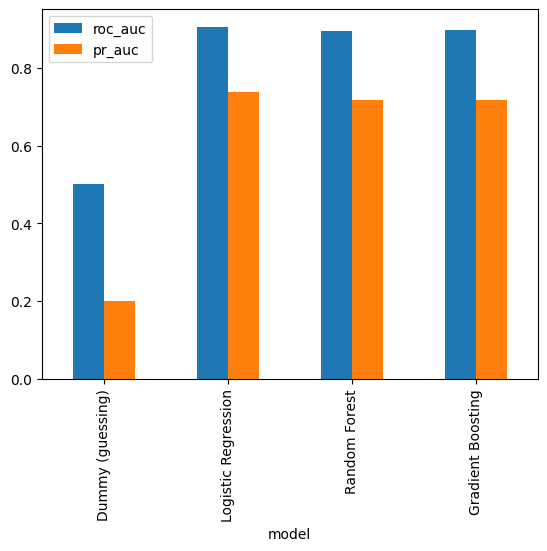

In [47]:
ax = results.set_index("model")[["roc_auc", "pr_auc"]].plot(kind = "bar")

In [48]:
best = models["Logistic Regression"]
best.fit(Xtr, ytr)
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
pred = best.predict(Xte)
#for roc and pr
proba = best.predict_proba(Xte)[:,1]

print("test ROC-AUC:", round(roc_auc_score(yte, proba), 3))
print("test PR-AUC: ", round(average_precision_score(yte, proba), 3))

print(classification_report(yte,pred, target_names=["Not viral", "Viral"]))


test ROC-AUC: 0.903
test PR-AUC:  0.731
              precision    recall  f1-score   support

   Not viral       0.89      0.94      0.91      1920
       Viral       0.69      0.54      0.60       480

    accuracy                           0.86      2400
   macro avg       0.79      0.74      0.76      2400
weighted avg       0.85      0.86      0.85      2400



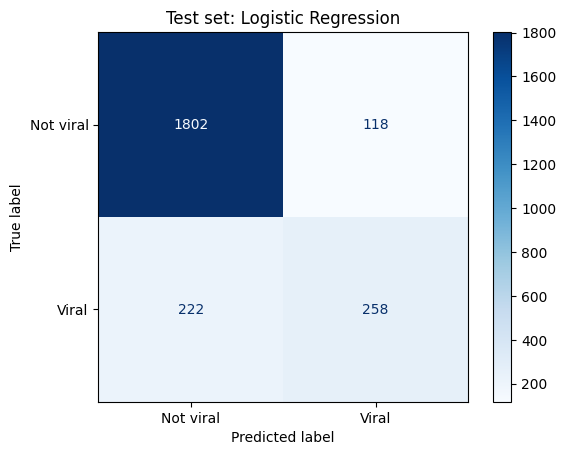

In [49]:
ConfusionMatrixDisplay.from_predictions(yte, pred,display_labels=["Not viral", "Viral"], cmap="Blues")
plt.title("Test set: " + "Logistic Regression")
plt.show()

# Turn to CSV for power bi

In [50]:
from sklearn.model_selection import cross_val_predict

export = raw.copy()

export["viral_label"] = export["viral"].map({0:"Not viral", 1: "Viral"})
export["face_label"]  = export["thumbnail_face"].map({0: "No face", 1: "Face"})

export["engagement_rate"] = (export["likes"] + export["comments"] + export["shares"]) / export["views"]
export["views_per_sub"]   = export["views"] / export["subscriber_count"]

# model's predicted chance of going viral, for every video
# (out-of-fold, so each prediction comes from a model that never saw that row)
export["pred_viral_prob"] = cross_val_predict(
    models["Gradient Boosting"], X, y, cv=cv, method="predict_proba"
)[:, 1]

export.to_csv("viral_videos_dashboard.csv", index=False)
print(export.shape)


(12000, 20)


In [51]:
from google.colab import files
files.download("viral_videos_dashboard.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>